# E204-DINO: replication and teacher-momentum controllability

Six new fixed-policy trajectories, then a conditional54-branch EMA study. Teacher and student, tasks and health outcomes remain separate. No predictor or MPC is launched.


## Progress and ETA (Stockholm)

```json
{
  "state": "running",
  "stage": "B seed2 state104 draw1 slow",
  "cursor": 8,
  "total": 32,
  "pid": 1717686,
  "updated": "2026-11-20T16:08:10.438625+01:00",
  "error": null,
  "completed_a": 6,
  "total_a": 6,
  "completed_b": 32,
  "total_b": 54,
  "eta": "2026-11-20T17:42:12.046647+01:00",
  "eta_note": "Stockholm. Remaining-trajectory upper estimate; initially excludes conditional EMA branches until the viability gate passes."
}
```


## Design

Two fresh seeds2/3 plus original pilot seed1; native pretrained DINO ViT-B/16, full pretrained heads, original primed center, fixed evaluation reservations, no replay. Six672-batch trajectories compare Full, Late4 and periodic Full. The new periodic arms match native DINO Late4 cost; old seed1 periodic matched SimSiam Late4 and remains context only. Skips freeze the whole learner and EMA clock. Applied momentum history is saved.

Phase-A viability requires at least two individual linear tasks improving by0.2pp on all three Full seeds, finite nondegenerate health, plausible teacher-signal variation and valid fresh periodic matches. A consistent5pp regression on a task blocks advancement; every smaller regression is reported too. LiDAR/MI are not required to increase. This is permission for a diagnostic study, not a claim of broadly better representations. Exact criteria are frozen in results/design.json.

If viable: Full source states64 (stable) and104 (post-shift), three source seeds, three fresh paired draws, three EMA rates. Fast/reference/slow scale **1-m_ref** by4/1/0.25, clamped to[0.98,1]. Intervene16 minibatches, then16 at the reference schedule. Student LR, centering, layer allocation and temperatures stay fixed. Readouts0/8/16/24/32; full eight-view health at0/16/32. Six source checkpoints and endpoint features permit reproduction without54 large endpoint models.

Independent-draw, task-specific diagnostic oracles are compared with reference momentum and a best fixed action selected on other seeds. Any teacher-feature association is exploratory; semantic labels never enter a deployed controller or training choices.


## Phase A: task-wise teacher gains

| Seed-policy | scene linear | weather linear | lighting linear | traffic light linear | pedestrian linear | scene kNN |
|---|---:|---:|---:|---:|---:|---:|
| 1-full | +2.407 | +0.267 | +0.847 | +1.397 | -1.932 | +1.756 |
| 1-late4 | +0.733 | -1.379 | +0.434 | +1.010 | -2.345 | -0.472 |
| 2-full | +3.001 | +0.090 | -0.460 | +0.928 | -3.251 | +0.847 |
| 2-late4 | +1.290 | -1.308 | +0.278 | +1.042 | -3.477 | -0.836 |
| 2-periodic | +1.757 | -0.780 | -0.546 | +1.501 | -3.226 | +0.589 |
| 3-full | +2.228 | -0.625 | +1.984 | +1.447 | -2.957 | +1.028 |
| 3-late4 | +0.957 | -2.043 | +0.179 | +0.942 | -2.838 | -0.579 |
| 3-periodic | +3.036 | -0.107 | +0.677 | +0.706 | -3.664 | +1.543 |

All values are percentage points versus the same pretrained teacher. Student, task regressions, timing and forward partial associations are retained in phase-a-summary.json.


## Phase-A viability gate

```json
{
  "passed": true,
  "teacher_tasks_improving_every_seed": [
    "scene linear",
    "traffic light linear"
  ],
  "consistent_catastrophic_regressions": [],
  "teacher_dynamics_varies": true,
  "finite_nondegenerate_health": true,
  "fresh_periodic_cost_matches": true,
  "all_full_task_changes": {
    "1": {
      "scene linear": 0.02406619167627766,
      "weather linear": 0.0026650896556333903,
      "lighting linear": 0.008467165446202629,
      "traffic light linear": 0.013969482054588478,
      "pedestrian linear": -0.01931914893617015,
      "scene kNN": 0.01756148562000215
    },
    "2": {
      "scene linear": 0.03001138063256703,
      "weather linear": 0.0008975054759007284,
      "lighting linear": -0.004604729978634037,
      "traffic light linear": 0.009277168851636985,
      "pedestrian linear": -0.03251063829787215,
      "scene kNN": 0.00847403390959961
    },
    "3": {
      "scene linear": 0.02228473087842342,
      "weather linear": -0.006245351666956389,
      "lighting linear": 0.019838380598930283,
      "traffic light linear": 0.014470950641163438,
      "pedestrian linear": -0.02957446808510622,
      "scene kNN": 0.010275511120912906
    }
  },
  "scope": "Viability for a bounded diagnostic EMA study, not a claim of general semantic improvement. Every task regression remains visible."
}
```


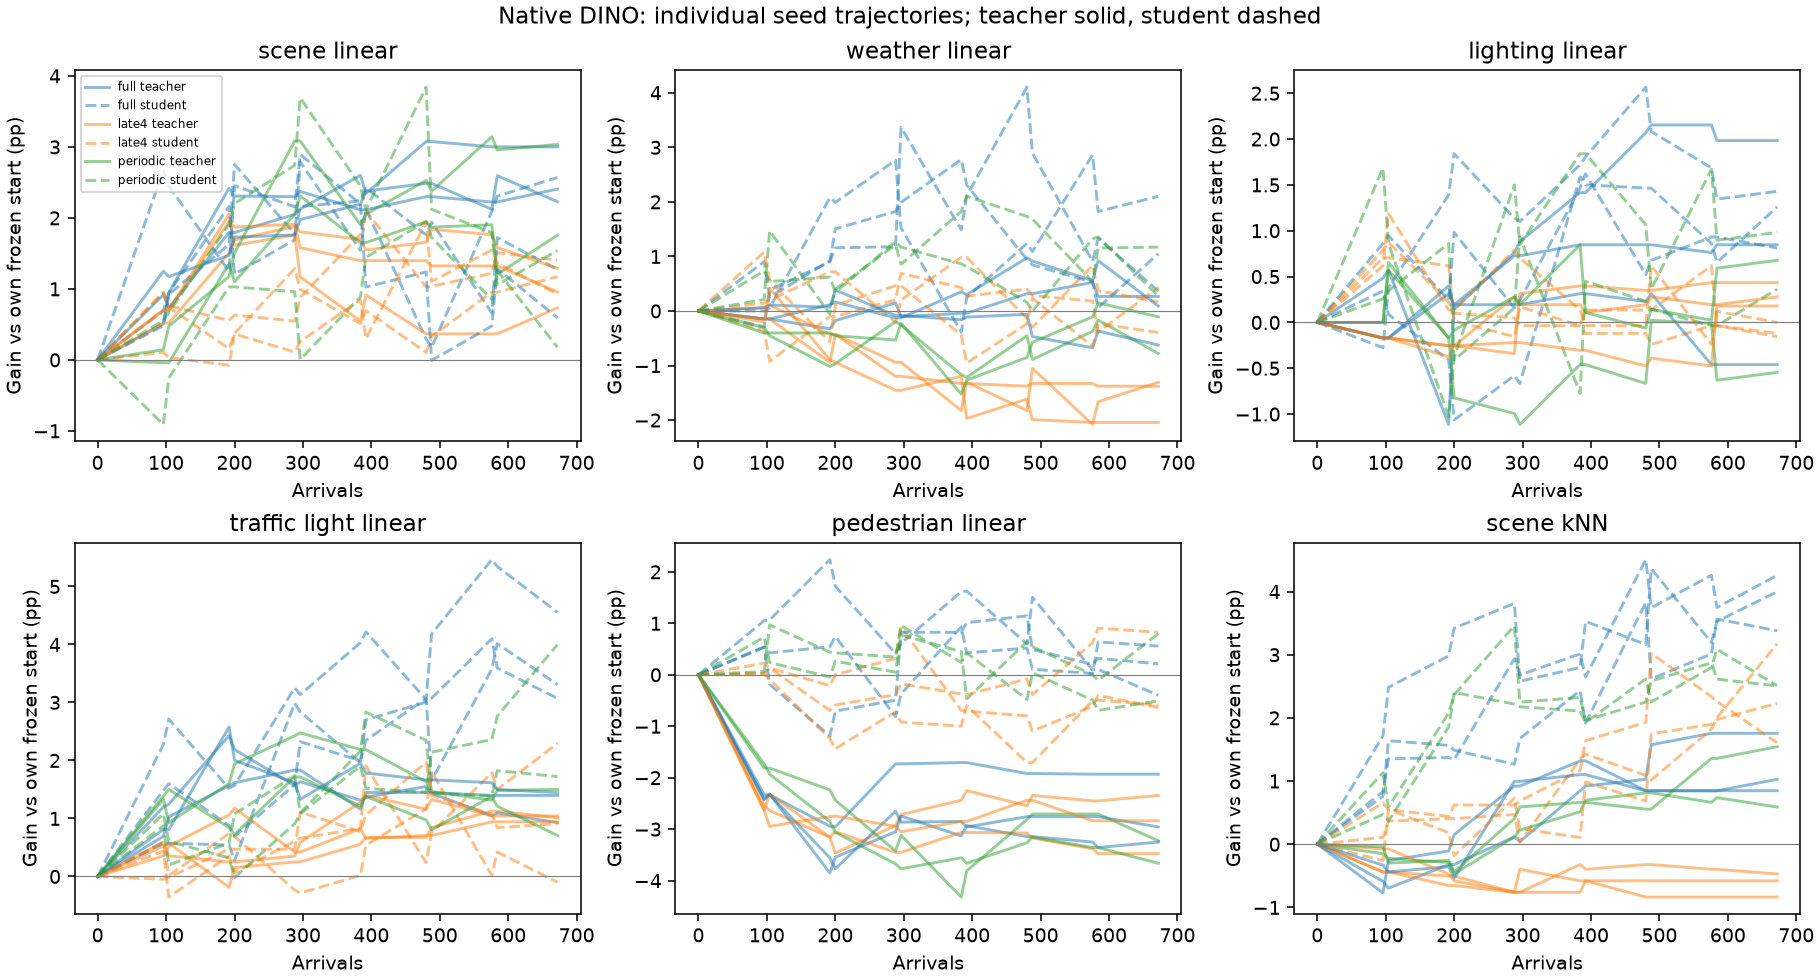